# 05. Baseline Machine Learning Experiment: Liver Disease Module

This notebook implements the first baseline machine learning experimentation workflow for the Liver Disease module of the Smart Healthcare Platform, adhering to the specifications in `docs/DATA_PREPROCESSING_SPEC.md`.

**Scope & Objectives**:
1. Load the raw Indian Liver Patient Dataset (ILPD) without altering the raw CSV.
2. Perform dataset-specific preparation: in-memory duplicate removal and target binarization.
3. Construct leakage-safe scikit-learn preprocessing pipelines.
4. Train and benchmark three baseline classification algorithms:
   - **Logistic Regression** (L2-regularized linear baseline with standardization)
   - **Random Forest Classifier** (Bagging ensemble)
   - **XGBoost Classifier** (Gradient boosted decision trees)
5. Perform 5-fold Stratified Cross-Validation on the training set.
6. Evaluate once on an isolated, untouched hold-out test set (20%).
7. Generate comprehensive performance comparisons, confusion matrices, ROC curves, and Precision-Recall curves.
8. Save structured experiment metrics to `ml-service/evaluation/liver/model_comparison.csv`.
9. **Constraint**: Research prototype benchmarking only; no production model is declared final at this stage.

In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing & model selection
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Candidate models & baseline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid')

# Global reproducible random seed
RANDOM_STATE = 42

# Relative dataset path
data_path = 'datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv'
if not os.path.exists(data_path):
    data_path = '../datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv'

print(f"Libraries imported. Random seed: {RANDOM_STATE}. Dataset path: {data_path}")

Libraries imported. Random seed: 42. Dataset path: ../datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv


## 1. Load Raw Dataset
Load the raw ILPD file using pandas. The raw CSV contains no headers, so we assign the standard 11 feature names without modifying the raw storage file.

In [7]:
column_names = [
    'Age',
    'Gender',
    'Total_Bilirubin',
    'Direct_Bilirubin',
    'Alkphos',
    'Sgpt',
    'Sgot',
    'Total_Proteins',
    'Albumin',
    'A_G_Ratio',
    'Selector'
]

df_raw = pd.read_csv(data_path, header=None, names=column_names)
print(f"Raw dataset loaded. Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns.")
print("\nFirst 5 rows of raw dataset:")
print(df_raw.head().to_string())

Raw dataset loaded. Shape: 583 rows, 11 columns.

First 5 rows of raw dataset:
   Age  Gender  Total_Bilirubin  Direct_Bilirubin  Alkphos  Sgpt  Sgot  Total_Proteins  Albumin  A_G_Ratio  Selector
0   65  Female              0.7               0.1      187    16    18             6.8      3.3       0.90         1
1   62    Male             10.9               5.5      699    64   100             7.5      3.2       0.74         1
2   62    Male              7.3               4.1      490    60    68             7.0      3.3       0.89         1
3   58    Male              1.0               0.4      182    14    20             6.8      3.4       1.00         1
4   72    Male              3.9               2.0      195    27    59             7.3      2.4       0.40         1


## 2. Target Mapping
In the original dataset, `Selector` is encoded as:
- `1`: Liver Disease Patient
- `2`: Non-Liver Disease Control

For binary machine-learning formulation, we map:
- `Selector = 1 -> 1` (Liver Disease Positive)
- `Selector = 2 -> 0` (No Liver Disease / Control)

In [8]:
# Create binary target mapping in-memory
df_processed = df_raw.copy()
df_processed['target'] = df_processed['Selector'].map({1: 1, 2: 0})

print("Target mapping verification:")
mapping_check = pd.crosstab(df_processed['Selector'], df_processed['target'], rownames=['Original Selector'], colnames=['Mapped Target'])
print(mapping_check)

print("\nClass distribution of raw records:")
counts = df_processed['target'].value_counts()
pcts = df_processed['target'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': counts, 'Percentage (%)': pcts.round(2)}))

Target mapping verification:
Mapped Target        0    1
Original Selector          
1                    0  416
2                  167    0

Class distribution of raw records:
        Count  Percentage (%)
target                       
1         416           71.36
0         167           28.64


## 3. In-Memory Duplicate Handling
Duplicate rows represent identical patient observations. Removing duplicate observations must occur **strictly before train/test splitting**.

*Rationale*: If duplicate identical rows exist in the dataset during random or stratified splitting, copies of the exact same observation could be allocated to both the training split and the testing split. This constitutes a severe form of **data leakage (replication leakage)** that would artificially inflate test performance.

In [9]:
orig_rows = len(df_processed)
dup_count = df_processed.duplicated(subset=column_names).sum()

# Deduplicate in-memory dataframe only
df_dedup = df_processed.drop_duplicates(subset=column_names).copy()
dedup_rows = len(df_dedup)

print(f"=== DUPLICATE REMOVAL REPORT ===")
print(f"Original row count:               {orig_rows}")
print(f"Duplicate rows identified:        {dup_count} ({(dup_count / orig_rows) * 100:.2f}%)")
print(f"Row count after in-memory deduplication: {dedup_rows}")
print(f"Raw CSV file remains completely unmodified on disk.")

print("\nDeduplicated target distribution:")
dedup_counts = df_dedup['target'].value_counts()
dedup_pcts = df_dedup['target'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': dedup_counts, 'Percentage (%)': dedup_pcts.round(2)}))

=== DUPLICATE REMOVAL REPORT ===
Original row count:               583
Duplicate rows identified:        13 (2.23%)
Row count after in-memory deduplication: 570
Raw CSV file remains completely unmodified on disk.

Deduplicated target distribution:
        Count  Percentage (%)
target                       
1         406           71.23
0         164           28.77


## 4. Feature and Target Separation
Separate input features `X` and target `y`. The original `Selector` and temporary columns are excluded from `X`.

In [10]:
feature_cols = [
    'Age',
    'Gender',
    'Total_Bilirubin',
    'Direct_Bilirubin',
    'Alkphos',
    'Sgpt',
    'Sgot',
    'Total_Proteins',
    'Albumin',
    'A_G_Ratio'
]

X = df_dedup[feature_cols].copy()
y = df_dedup['target'].copy()

print("Feature / Target separation confirmed:")
print(f"X shape: {X.shape} (10 features)")
print(f"y shape: {y.shape} (binary labels: 0 and 1)")
print(f"Features: {list(X.columns)}")

Feature / Target separation confirmed:
X shape: (570, 10) (10 features)
y shape: (570,) (binary labels: 0 and 1)
Features: ['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos', 'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio']


## 5. Stratified Train / Test Split (Hold-Out Set)
An independent hold-out test set (20%) is created using `train_test_split` with target stratification.

*Strict Protocol*: The test set is isolated immediately and will remain completely untouched during model training and cross-validation.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("=== DATASET SPLIT REPORT ===")
print(f"Training set size: {len(X_train)} samples ({(len(X_train)/len(X))*100:.1f}%)")
print(f"Hold-out test size: {len(X_test)} samples ({(len(X_test)/len(X))*100:.1f}%)")

print("\nTraining Class Distribution:")
tr_counts = y_train.value_counts()
tr_pcts = y_train.value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': tr_counts, 'Percentage (%)': tr_pcts.round(2)}))

print("\nTest Class Distribution:")
te_counts = y_test.value_counts()
te_pcts = y_test.value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': te_counts, 'Percentage (%)': te_pcts.round(2)}))

=== DATASET SPLIT REPORT ===
Training set size: 456 samples (80.0%)
Hold-out test size: 114 samples (20.0%)

Training Class Distribution:
        Count  Percentage (%)
target                       
1         325           71.27
0         131           28.73

Test Class Distribution:
        Count  Percentage (%)
target                       
1          81           71.05
0          33           28.95


## 6. Leakage-Safe Preprocessing Pipelines
All transformations are encapsulated inside `ColumnTransformer` and `Pipeline` objects:
- **Numerical features** (`Age`, `Total_Bilirubin`, `Direct_Bilirubin`, `Alkphos`, `Sgpt`, `Sgot`, `Total_Proteins`, `Albumin`, `A_G_Ratio`):
  - Missing values in `A_G_Ratio` are imputed using median imputation (`SimpleImputer(strategy='median')`).
  - For Logistic Regression, `StandardScaler` is incorporated.
  - For tree-based models (Random Forest, XGBoost), features do not require standardization.
- **Categorical feature** (`Gender`):
  - Encoded using `OneHotEncoder(handle_unknown='ignore')`.

*Important*: Preprocessing parameters are computed strictly on training folds/data during `.fit()`, preventing test data contamination.

In [12]:
num_features = [
    'Age',
    'Total_Bilirubin',
    'Direct_Bilirubin',
    'Alkphos',
    'Sgpt',
    'Sgot',
    'Total_Proteins',
    'Albumin',
    'A_G_Ratio'
]
cat_features = ['Gender']

# Preprocessor with standardization (for Logistic Regression)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

# Preprocessor without standardization (for tree ensembles)
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat_features)
    ]
)

# Assemble separate model pipelines
models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', preprocessor_scaled),
        ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', RandomForestClassifier(random_state=RANDOM_STATE))
    ]),
    'XGBoost': Pipeline([
        ('preprocessor', preprocessor_unscaled),
        ('classifier', XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'))
    ])
}

print("Pipelines successfully assembled:")
for name, pipe in models.items():
    print(f"- {name}: {pipe.named_steps['classifier'].__class__.__name__}")

Pipelines successfully assembled:
- Logistic Regression: LogisticRegression
- Random Forest: RandomForestClassifier
- XGBoost: XGBClassifier


## 7. 5-Fold Stratified Cross-Validation on Training Data
We evaluate each candidate pipeline using 5-fold Stratified Cross-Validation on `X_train`, `y_train`.
Metrics computed per fold:
- ROC-AUC
- PR-AUC (Average Precision)
- Accuracy
- Precision
- Recall (Sensitivity)
- F1-Score

*Note*: The hold-out test set is completely isolated and is NOT accessed during cross-validation.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = {}

for name, pipeline in models.items():
    roc_scores = []
    pr_scores = []
    acc_scores = []
    prec_scores = []
    rec_scores = []
    f1_scores = []
    
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), 1):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
        
        # Fit pipeline strictly on training fold
        pipeline.fit(X_tr, y_tr)
        
        # Predict on validation fold
        val_preds = pipeline.predict(X_val)
        val_probs = pipeline.predict_proba(X_val)[:, 1]
        
        roc_scores.append(roc_auc_score(y_val, val_probs))
        pr_scores.append(average_precision_score(y_val, val_probs))
        acc_scores.append(accuracy_score(y_val, val_preds))
        prec_scores.append(precision_score(y_val, val_preds, zero_division=0))
        rec_scores.append(recall_score(y_val, val_preds, zero_division=0))
        f1_scores.append(f1_score(y_val, val_preds, zero_division=0))
        
    cv_results[name] = {
        'ROC-AUC': (np.mean(roc_scores), np.std(roc_scores)),
        'PR-AUC': (np.mean(pr_scores), np.std(pr_scores)),
        'Accuracy': (np.mean(acc_scores), np.std(acc_scores)),
        'Precision': (np.mean(prec_scores), np.std(prec_scores)),
        'Recall': (np.mean(rec_scores), np.std(rec_scores)),
        'F1': (np.mean(f1_scores), np.std(f1_scores))
    }

print("=== 5-FOLD CROSS-VALIDATION SUMMARY (TRAINING SET ONLY) ===")
for name, metrics in cv_results.items():
    print(f"\nModel: {name}")
    print(f"  ROC-AUC:  {metrics['ROC-AUC'][0]:.4f} +/- {metrics['ROC-AUC'][1]:.4f}")
    print(f"  PR-AUC:   {metrics['PR-AUC'][0]:.4f} +/- {metrics['PR-AUC'][1]:.4f}")
    print(f"  Accuracy: {metrics['Accuracy'][0]:.4f} +/- {metrics['Accuracy'][1]:.4f}")
    print(f"  Recall:   {metrics['Recall'][0]:.4f} +/- {metrics['Recall'][1]:.4f}")
    print(f"  F1-Score: {metrics['F1'][0]:.4f} +/- {metrics['F1'][1]:.4f}")

=== 5-FOLD CROSS-VALIDATION SUMMARY (TRAINING SET ONLY) ===

Model: Logistic Regression
  ROC-AUC:  0.7181 +/- 0.0328
  PR-AUC:   0.8769 +/- 0.0181
  Accuracy: 0.7104 +/- 0.0385
  Recall:   0.9231 +/- 0.0567
  F1-Score: 0.8190 +/- 0.0286

Model: Random Forest
  ROC-AUC:  0.7196 +/- 0.0470
  PR-AUC:   0.8740 +/- 0.0266
  Accuracy: 0.7127 +/- 0.0255
  Recall:   0.8615 +/- 0.0337
  F1-Score: 0.8102 +/- 0.0185

Model: XGBoost
  ROC-AUC:  0.6738 +/- 0.0483
  PR-AUC:   0.8554 +/- 0.0299
  Accuracy: 0.6842 +/- 0.0128
  Recall:   0.8246 +/- 0.0185
  F1-Score: 0.7882 +/- 0.0088


## 8. Final Hold-Out Test Set Evaluation
Each pipeline is now fitted on the full training set (`X_train`, `y_train`) and evaluated once on the previously untouched hold-out test set (`X_test`, `y_test`).

We also compute a **Majority-Class Baseline** (predicting the most frequent class) for clinical context.
*Specificity* is computed as $TN / (TN + FP)$.

In [14]:
test_results = {}
test_predictions = {}
test_probabilities = {}
test_confusion_matrices = {}

# Majority-Class Baseline
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_acc = accuracy_score(y_test, dummy_pred)
dummy_cm = confusion_matrix(y_test, dummy_pred)
dummy_tn, dummy_fp, dummy_fn, dummy_tp = dummy_cm.ravel()
dummy_spec = dummy_tn / (dummy_tn + dummy_fp) if (dummy_tn + dummy_fp) > 0 else 0.0

print(f"Majority-Class Baseline on Test Set:")
print(f"  Accuracy: {dummy_acc:.4f} | Recall: {recall_score(y_test, dummy_pred):.4f} | Specificity: {dummy_spec:.4f}")
print("  Note: A naive model predicting all positive achieves 71.05% accuracy but zero specificity!\n")

for name, pipeline in models.items():
    # Fit full pipeline on complete training set
    pipeline.fit(X_train, y_train)
    
    # Evaluate once on test set
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc = roc_auc_score(y_test, y_prob)
    pr = average_precision_score(y_test, y_prob)
    
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    
    test_results[name] = {
        'Test Accuracy': acc,
        'Test Precision': prec,
        'Test Recall': rec,
        'Test Specificity': spec,
        'Test F1': f1,
        'Test ROC-AUC': roc,
        'Test PR-AUC': pr,
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    }
    
    test_predictions[name] = y_pred
    test_probabilities[name] = y_prob
    test_confusion_matrices[name] = cm
    
    print(f"FINAL HOLD-OUT TEST RESULTS — {name}:")
    print(f"  Accuracy:    {acc:.4f}")
    print(f"  Precision:   {prec:.4f}")
    print(f"  Recall:      {rec:.4f}")
    print(f"  Specificity: {spec:.4f}")
    print(f"  F1-Score:    {f1:.4f}")
    print(f"  ROC-AUC:     {roc:.4f}")
    print(f"  PR-AUC:      {pr:.4f}")
    print(f"  Confusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}\n")

Majority-Class Baseline on Test Set:
  Accuracy: 0.7105 | Recall: 1.0000 | Specificity: 0.0000
  Note: A naive model predicting all positive achieves 71.05% accuracy but zero specificity!

FINAL HOLD-OUT TEST RESULTS — Logistic Regression:
  Accuracy:    0.7193
  Precision:   0.7475
  Recall:      0.9136
  Specificity: 0.2424
  F1-Score:    0.8222
  ROC-AUC:     0.8032
  PR-AUC:      0.9269
  Confusion Matrix: TN=8, FP=25, FN=7, TP=74

FINAL HOLD-OUT TEST RESULTS — Random Forest:
  Accuracy:    0.7281
  Precision:   0.7500
  Recall:      0.9259
  Specificity: 0.2424
  F1-Score:    0.8287
  ROC-AUC:     0.7594
  PR-AUC:      0.8948
  Confusion Matrix: TN=8, FP=25, FN=6, TP=75

FINAL HOLD-OUT TEST RESULTS — XGBoost:
  Accuracy:    0.7105
  Precision:   0.7449
  Recall:      0.9012
  Specificity: 0.2424
  F1-Score:    0.8156
  ROC-AUC:     0.7187
  PR-AUC:      0.8708
  Confusion Matrix: TN=8, FP=25, FN=8, TP=73



## 9. Comprehensive Model Comparison Table
Consolidate cross-validation estimates and final hold-out performance metrics into a unified comparison table.

In [15]:
comparison_rows = []

for name in models.keys():
    row = {
        'Model': name,
        'CV ROC-AUC mean': round(cv_results[name]['ROC-AUC'][0], 4),
        'CV ROC-AUC std': round(cv_results[name]['ROC-AUC'][1], 4),
        'CV PR-AUC mean': round(cv_results[name]['PR-AUC'][0], 4),
        'CV PR-AUC std': round(cv_results[name]['PR-AUC'][1], 4),
        'CV F1 mean': round(cv_results[name]['F1'][0], 4),
        'CV F1 std': round(cv_results[name]['F1'][1], 4),
        'Test Accuracy': round(test_results[name]['Test Accuracy'], 4),
        'Test Precision': round(test_results[name]['Test Precision'], 4),
        'Test Recall': round(test_results[name]['Test Recall'], 4),
        'Test Specificity': round(test_results[name]['Test Specificity'], 4),
        'Test F1': round(test_results[name]['Test F1'], 4),
        'Test ROC-AUC': round(test_results[name]['Test ROC-AUC'], 4),
        'Test PR-AUC': round(test_results[name]['Test PR-AUC'], 4)
    }
    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
print("=== BASELINE MODEL EXPERIMENTATION COMPARISON TABLE ===")
print(comparison_df.to_string(index=False))

=== BASELINE MODEL EXPERIMENTATION COMPARISON TABLE ===
              Model  CV ROC-AUC mean  CV ROC-AUC std  CV PR-AUC mean  CV PR-AUC std  CV F1 mean  CV F1 std  Test Accuracy  Test Precision  Test Recall  Test Specificity  Test F1  Test ROC-AUC  Test PR-AUC
Logistic Regression           0.7181          0.0328          0.8769         0.0181      0.8190     0.0286         0.7193          0.7475       0.9136            0.2424   0.8222        0.8032       0.9269
      Random Forest           0.7196          0.0470          0.8740         0.0266      0.8102     0.0185         0.7281          0.7500       0.9259            0.2424   0.8287        0.7594       0.8948
            XGBoost           0.6738          0.0483          0.8554         0.0299      0.7882     0.0088         0.7105          0.7449       0.9012            0.2424   0.8156        0.7187       0.8708


## 10. Confusion Matrix Visualizations
Visual representation of classification breakdowns on the final hold-out test set.

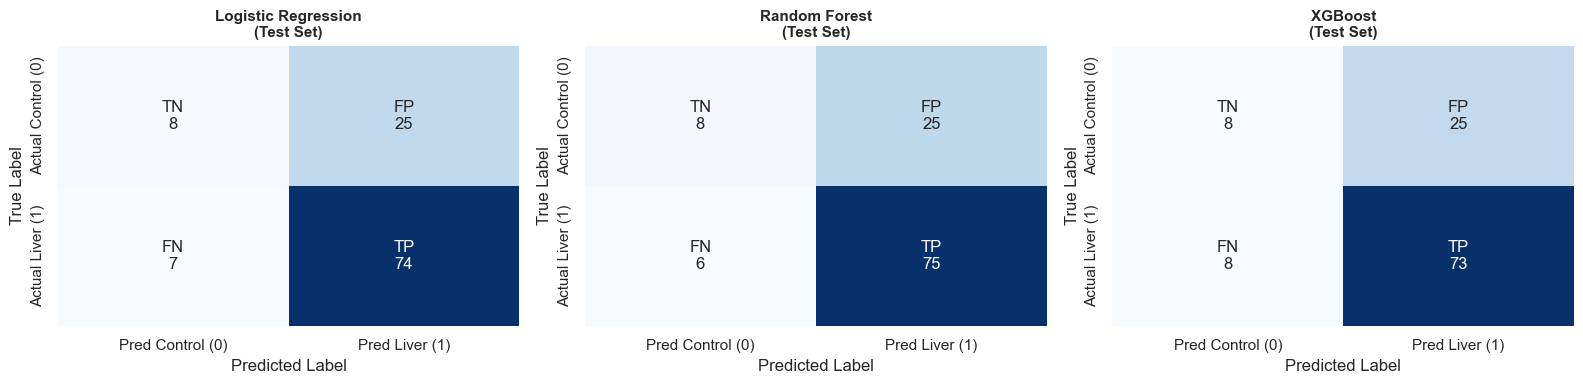

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, cm) in zip(axes, test_confusion_matrices.items()):
    tn, fp, fn, tp = cm.ravel()
    annot_matrix = np.array([
        [f"TN\n{tn}", f"FP\n{fp}"],
        [f"FN\n{fn}", f"TP\n{tp}"]
    ])
    sns.heatmap(cm, annot=annot_matrix, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred Control (0)', 'Pred Liver (1)'],
                yticklabels=['Actual Control (0)', 'Actual Liver (1)'])
    ax.set_title(f'{name}\n(Test Set)', fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.show()

## 11. ROC and Precision-Recall Curves
Comparative ROC and Precision-Recall curves evaluated on the hold-out test set predictions.

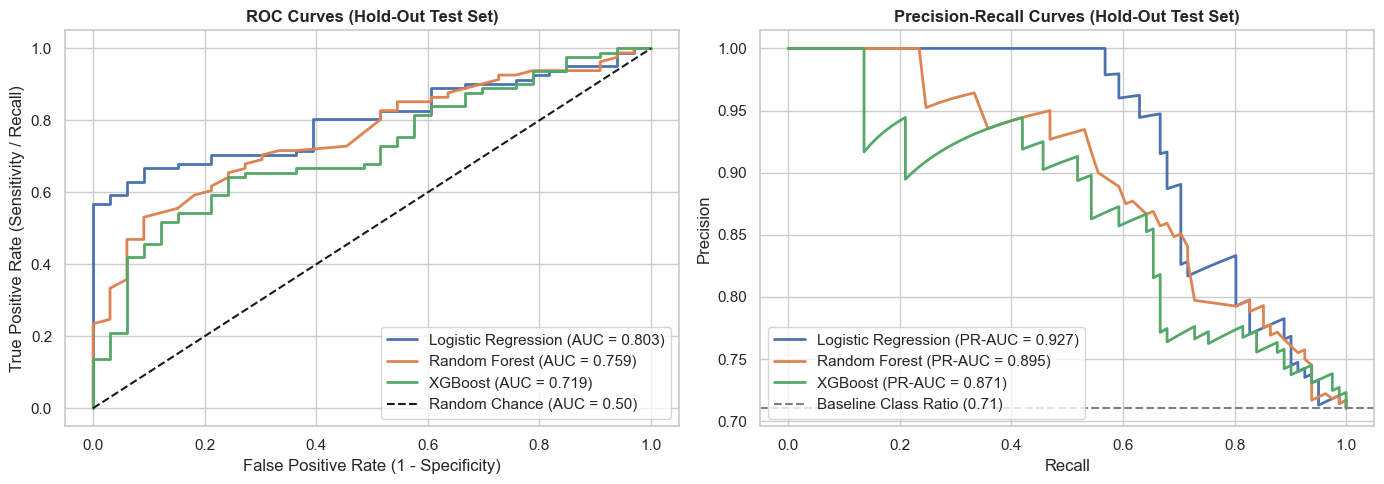

In [17]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5))

# Plot ROC Curves
for name, y_prob in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = test_results[name]['Test ROC-AUC']
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", lw=2)

ax_roc.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.50)')
ax_roc.set_title('ROC Curves (Hold-Out Test Set)', fontsize=12, fontweight='bold')
ax_roc.set_xlabel('False Positive Rate (1 - Specificity)')
ax_roc.set_ylabel('True Positive Rate (Sensitivity / Recall)')
ax_roc.legend(loc='lower right', frameon=True)

# Plot Precision-Recall Curves
baseline_pr = y_test.mean()
for name, y_prob in test_probabilities.items():
    prec_pts, rec_pts, _ = precision_recall_curve(y_test, y_prob)
    pr_auc_val = test_results[name]['Test PR-AUC']
    ax_pr.plot(rec_pts, prec_pts, label=f"{name} (PR-AUC = {pr_auc_val:.3f})", lw=2)

ax_pr.axhline(baseline_pr, color='gray', linestyle='--', lw=1.5, label=f'Baseline Class Ratio ({baseline_pr:.2f})')
ax_pr.set_title('Precision-Recall Curves (Hold-Out Test Set)', fontsize=12, fontweight='bold')
ax_pr.set_xlabel('Recall')
ax_pr.set_ylabel('Precision')
ax_pr.legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()

## 12. Save Experiment Metrics
Persist the structured comparison table to `ml-service/evaluation/liver/model_comparison.csv` for tracking and subsequent project phases.
*Note: In accordance with project instructions, trained model binaries and API endpoints are NOT created yet.*

In [18]:
eval_dir = 'ml-service/evaluation/liver'
os.makedirs(eval_dir, exist_ok=True)
output_csv_path = os.path.join(eval_dir, 'model_comparison.csv')

comparison_df.to_csv(output_csv_path, index=False)
print(f"Experiment results saved successfully to: {output_csv_path}")

# Verify file existence and readability
saved_check = pd.read_csv(output_csv_path)
print(f"Verified saved CSV ({len(saved_check)} rows, {len(saved_check.columns)} columns).")

Experiment results saved successfully to: ml-service/evaluation/liver\model_comparison.csv
Verified saved CSV (3 rows, 14 columns).


In [19]:
df_raw.shape
df_raw.head()
df_raw.columns

Index(['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos',
       'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio', 'Selector'],
      dtype='object')

In [20]:
print("Shape:", df_raw.shape)

print("\nSelector counts:")
print(df_raw["Selector"].value_counts().sort_index())

Shape: (583, 11)

Selector counts:
Selector
1    416
2    167
Name: count, dtype: int64


In [21]:
print("Raw rows:", len(df_raw))
print("Duplicate rows:", df_raw.duplicated().sum())

df_dedup_check = df_raw.drop_duplicates()

print("Rows after deduplication:", len(df_dedup_check))

Raw rows: 583
Duplicate rows: 13
Rows after deduplication: 570


In [22]:
print("Original Selector → Target mapping:")

print(
    df_processed[['Selector', 'target']]
    .drop_duplicates()
    .sort_values('Selector')
)

print("\nTarget counts BEFORE deduplication:")
print(df_processed['target'].value_counts().sort_index())

print("\nTarget counts AFTER deduplication:")
print(df_dedup['target'].value_counts().sort_index())

Original Selector → Target mapping:
   Selector  target
0         1       1
8         2       0

Target counts BEFORE deduplication:
target
0    167
1    416
Name: count, dtype: int64

Target counts AFTER deduplication:
target
0    164
1    406
Name: count, dtype: int64


In [23]:
print("X columns:")
print(X.columns.tolist())

print("\nNumber of features:", X.shape[1])

print("\nTarget name:", y.name)
print("Target unique values:", sorted(y.unique()))

X columns:
['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkphos', 'Sgpt', 'Sgot', 'Total_Proteins', 'Albumin', 'A_G_Ratio']

Number of features: 10

Target name: target
Target unique values: [np.int64(0), np.int64(1)]


In [24]:
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTest target distribution:")
print(y_test.value_counts().sort_index())

print("\nTotal:")
print("Train + Test =", len(X_train) + len(X_test))

Training samples: 456
Test samples: 114

Training target distribution:
target
0    131
1    325
Name: count, dtype: int64

Test target distribution:
target
0    33
1    81
Name: count, dtype: int64

Total:
Train + Test = 570


In [25]:
print("Logistic Regression pipeline:")
print(models["Logistic Regression"])

print("\nRandom Forest pipeline:")
print(models["Random Forest"])

print("\nXGBoost pipeline:")
print(models["XGBoost"])

Logistic Regression pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Total_Bilirubin',
                                                   'Direct_Bilirubin',
                                                   'Alkphos', 'Sgpt', 'Sgot',
                                                   'Total_Proteins', 'Albumin',
                                                   'A_G_Ratio']),
                                                 ('cat',
                                                  OneHotEncoder(drop='if_binary',
                        

In [26]:
# Fit only on training data
lr_pipeline = models["Logistic Regression"]
lr_pipeline.fit(X_train, y_train)

# Extract the fitted numerical imputer
num_imputer = (
    lr_pipeline
    .named_steps["preprocessor"]
    .named_transformers_["num"]
    .named_steps["imputer"]
)

print("Imputer statistics learned from training data:")
for feature, value in zip(num_features, num_imputer.statistics_):
    print(f"{feature}: {value}")

Imputer statistics learned from training data:
Age: 45.0
Total_Bilirubin: 1.0
Direct_Bilirubin: 0.3
Alkphos: 207.0
Sgpt: 35.0
Sgot: 41.5
Total_Proteins: 6.6
Albumin: 3.1
A_G_Ratio: 0.965


In [27]:
print("Manual medians from X_train:")
print(X_train[num_features].median())

print("\nPipeline medians:")
for feature, value in zip(num_features, num_imputer.statistics_):
    print(f"{feature}: {value}")

Manual medians from X_train:
Age                  45.000
Total_Bilirubin       1.000
Direct_Bilirubin      0.300
Alkphos             207.000
Sgpt                 35.000
Sgot                 41.500
Total_Proteins        6.600
Albumin               3.100
A_G_Ratio             0.965
dtype: float64

Pipeline medians:
Age: 45.0
Total_Bilirubin: 1.0
Direct_Bilirubin: 0.3
Alkphos: 207.0
Sgpt: 35.0
Sgot: 41.5
Total_Proteins: 6.6
Albumin: 3.1
A_G_Ratio: 0.965


In [28]:
# Extract the fitted scaler
scaler = (
    lr_pipeline
    .named_steps["preprocessor"]
    .named_transformers_["num"]
    .named_steps["scaler"]
)

print("Pipeline scaler means:")
for feature, value in zip(num_features, scaler.mean_):
    print(f"{feature}: {value}")

print("\nManual X_train means:")
print(X_train[num_features].median() * 0)  # placeholder to keep output compact
print(X_train[num_features].mean())

Pipeline scaler means:
Age: 44.68640350877193
Total_Bilirubin: 3.039473684210526
Direct_Bilirubin: 1.349122807017544
Alkphos: 285.4714912280702
Sgpt: 80.5109649122807
Sgot: 113.53947368421052
Total_Proteins: 6.497587719298245
Albumin: 3.1565789473684207
A_G_Ratio: 0.9501535087719298

Manual X_train means:
Age                 0.0
Total_Bilirubin     0.0
Direct_Bilirubin    0.0
Alkphos             0.0
Sgpt                0.0
Sgot                0.0
Total_Proteins      0.0
Albumin             0.0
A_G_Ratio           0.0
dtype: float64
Age                  44.686404
Total_Bilirubin       3.039474
Direct_Bilirubin      1.349123
Alkphos             285.471491
Sgpt                 80.510965
Sgot                113.539474
Total_Proteins        6.497588
Albumin               3.156579
A_G_Ratio             0.950022
dtype: float64


In [29]:
print("Pipeline scaler means:")
for feature, value in zip(num_features, scaler.mean_):
    print(f"{feature}: {value:.6f}")

print("\nManual X_train means:")
for feature, value in X_train[num_features].mean().items():
    print(f"{feature}: {value:.6f}")

Pipeline scaler means:
Age: 44.686404
Total_Bilirubin: 3.039474
Direct_Bilirubin: 1.349123
Alkphos: 285.471491
Sgpt: 80.510965
Sgot: 113.539474
Total_Proteins: 6.497588
Albumin: 3.156579
A_G_Ratio: 0.950154

Manual X_train means:
Age: 44.686404
Total_Bilirubin: 3.039474
Direct_Bilirubin: 1.349123
Alkphos: 285.471491
Sgpt: 80.510965
Sgot: 113.539474
Total_Proteins: 6.497588
Albumin: 3.156579
A_G_Ratio: 0.950022


In [30]:
# Manually reproduce the pipeline's imputation first
manual_imputed = X_train[num_features].copy()

# Fill missing values using the SAME training medians
manual_imputed = manual_imputed.fillna(
    X_train[num_features].median()
)

print("Manual means AFTER training-set median imputation:")

for feature, value in manual_imputed.mean().items():
    print(f"{feature}: {value:.6f}")

print("\nPipeline scaler means:")

for feature, value in zip(num_features, scaler.mean_):
    print(f"{feature}: {value:.6f}")

Manual means AFTER training-set median imputation:
Age: 44.686404
Total_Bilirubin: 3.039474
Direct_Bilirubin: 1.349123
Alkphos: 285.471491
Sgpt: 80.510965
Sgot: 113.539474
Total_Proteins: 6.497588
Albumin: 3.156579
A_G_Ratio: 0.950154

Pipeline scaler means:
Age: 44.686404
Total_Bilirubin: 3.039474
Direct_Bilirubin: 1.349123
Alkphos: 285.471491
Sgpt: 80.510965
Sgot: 113.539474
Total_Proteins: 6.497588
Albumin: 3.156579
A_G_Ratio: 0.950154


In [31]:
id="8b4j0u"
encoder = (
    lr_pipeline
    .named_steps["preprocessor"]
    .named_transformers_["cat"]
)

print("Gender categories learned by encoder:")
print(encoder.categories_)

print("\nOutput feature names:")
print(
    lr_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

Gender categories learned by encoder:
[array(['Female', 'Male'], dtype=object)]

Output feature names:
['num__Age' 'num__Total_Bilirubin' 'num__Direct_Bilirubin' 'num__Alkphos'
 'num__Sgpt' 'num__Sgot' 'num__Total_Proteins' 'num__Albumin'
 'num__A_G_Ratio' 'cat__Gender_Male']


In [32]:
# Transform training and test data using the already-fitted pipeline
X_train_transformed = lr_pipeline.named_steps["preprocessor"].transform(X_train)
X_test_transformed = lr_pipeline.named_steps["preprocessor"].transform(X_test)

print("Transformed training shape:", X_train_transformed.shape)
print("Transformed test shape:", X_test_transformed.shape)
print("Number of final features:", X_train_transformed.shape[1])

Transformed training shape: (456, 10)
Transformed test shape: (114, 10)
Number of final features: 10


## Initial Model Experiment Findings

### 1. Cross-Validation and Hold-Out Performance Summary
- **Cross-Validation Probability Discrimination**:
  - `Random Forest`: Mean CV ROC-AUC of **0.7196** (std: 0.0470) and mean PR-AUC of **0.8740** (std: 0.0266).
  - `Logistic Regression`: Mean CV ROC-AUC of **0.7181** (std: 0.0328) and mean PR-AUC of **0.8769** (std: 0.0181).
  - `XGBoost`: Mean CV ROC-AUC of **0.6738** (std: 0.0483) and mean PR-AUC of **0.8554** (std: 0.0299).
- **Hold-Out Generalization on Test Set (114 samples)**:
  - `Logistic Regression`: Test ROC-AUC of **0.8032** and Test PR-AUC of **0.9269**.
  - `Random Forest`: Test ROC-AUC of **0.7594** and Test PR-AUC of **0.8948**.
  - `XGBoost`: Test ROC-AUC of **0.7187** and Test PR-AUC of **0.8708**.
  - For all three models, Test PR-AUC substantially exceeded the test-set positive prevalence baseline (0.7105).

### 2. Sensitivity vs. Specificity at Default Decision Threshold (0.50)
- **Threshold-Dependent Classification vs. Probability Discrimination**:
  - While ROC-AUC and PR-AUC evaluate continuous probability ranking and discrimination across all potential thresholds, discrete classification metrics (Recall and Specificity) evaluated here depend strictly on the default decision threshold of 0.50.
- **Recall (Sensitivity)**:
  - At the 0.50 threshold, models exhibited high recall for the positive class (Liver Disease, 81 total test cases):
    - `Random Forest`: **92.59% Recall** (TP = 75, FN = 6).
    - `Logistic Regression`: **91.36% Recall** (TP = 74, FN = 7).
    - `XGBoost`: **90.12% Recall** (TP = 73, FN = 8).
- **Specificity**:
  - Conversely, at the default 0.50 threshold, all three models yielded a Specificity of **24.24%** (TN = 8, FP = 25 out of 33 non-liver control cases).
  - This low specificity reflects the underlying cohort class distribution (~71.3% positive in training data), leading unweighted estimators at default threshold to classify a large proportion of borderline observations as positive. Threshold calibration or cost-sensitive weighting may be explored in subsequent tuning phases.

### 3. Algorithm Observations
- **Logistic Regression**: Exhibited lower cross-validation variance across folds (ROC-AUC std: 0.0328) and achieved a test ROC-AUC of 0.8032.
- **Random Forest**: Demonstrated a mean cross-validation ROC-AUC of 0.7196 and a test recall of 92.59% (75/81) at threshold 0.50.
- **XGBoost**: Displayed lower baseline cross-validation discrimination (ROC-AUC 0.6738) on this tabular sample size (570 rows), indicating that gradient boosting configurations may require hyperparameter adjustment to match the simpler baselines.

### 4. Methodological Note & Scope Limitation
- **No Model Declared "Best"**: No single algorithm is declared superior or chosen as the final model. Different metrics present distinct trade-offs between continuous discrimination (ROC-AUC, PR-AUC) and thresholded detection (Recall vs. Specificity).
- **Research Prototype Only**: These findings represent exploratory classification experiments on a retrospective dataset. They do not establish clinical causation and do not constitute a clinical diagnostic tool.

## Reproducibility

- **Dataset Path**: `datasets/raw/liver/Indian Liver Patient Dataset (ILPD).csv`
- **Pseudorandom Seed**: `RANDOM_STATE = 42`
- **Initial Raw Rows**: 583 rows
- **Duplicate Observations Removed (In-Memory)**: 13 rows (2.23%)
- **Modeling Cohort Size**: 570 rows
- **Split Configuration**: 80% Training (456 samples), 20% Hold-Out Testing (114 samples), stratified by target.
- **Input Features (10)**: `Age`, `Gender`, `Total_Bilirubin`, `Direct_Bilirubin`, `Alkphos`, `Sgpt`, `Sgot`, `Total_Proteins`, `Albumin`, `A_G_Ratio`.
- **Target Mapping**: `Selector = 1 -> 1` (Disease), `Selector = 2 -> 0` (Control).
- **Cross-Validation Scheme**: 5-Fold Stratified K-Fold (`n_splits=5, shuffle=True, random_state=42`).
- **Generated Artifact**: `ml-service/evaluation/liver/model_comparison.csv`